<a href="https://colab.research.google.com/github/luffy-loop/ML_Project/blob/main/MLProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# ============================================================
# AI-POWERED STUDENT PERFORMANCE & SUCCESS PREDICTION
# ============================================================

!pip -q install catboost

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import csv
import os

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

from catboost import CatBoostClassifier

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 7.1 MB/s eta 0:00:00


In [2]:
from google.colab import files

uploaded = files.upload()

Saving assessments.csv to assessments.csv
Saving studentAssessment.csv to studentAssessment.csv
Saving studentInfo.csv to studentInfo.csv
Saving studentVle.csv to studentVle.csv


In [20]:
import os

print(os.listdir())

['.config', 'studentAssessment.csv', 'assessments.csv', 'studentInfo.csv', 'studentVle.csv', 'catboost_info', 'sample_data']


In [3]:
# ============================================================
# LOAD DATA
# ============================================================

student_info = pd.read_csv("studentInfo.csv")

student_assessment = pd.read_csv(
    "studentAssessment.csv"
)

assessments = pd.read_csv(
    "assessments.csv"
)

# studentVle has a malformed quoted row in your file,
# so use Python engine.
student_vle = pd.read_csv(
    "studentVle.csv",
    engine="python",
    on_bad_lines="skip"
)

print("Student Info:", student_info.shape)
print("Student Assessment:", student_assessment.shape)
print("Assessments:", assessments.shape)
print("Student VLE:", student_vle.shape)

Student Info: (32593, 12)
Student Assessment: (173912, 5)
Assessments: (206, 6)
Student VLE: (10655280, 6)


In [4]:
# ============================================================
# TARGET CREATION
# ============================================================

student_info["At_Risk"] = student_info["final_result"].map({
    "Withdrawn": 1,
    "Fail": 1,
    "Pass": 0,
    "Distinction": 0
})

student_info = student_info.dropna(
    subset=["At_Risk"]
)

student_info["At_Risk"] = (
    student_info["At_Risk"]
    .astype(int)
)

print(
    student_info["At_Risk"].value_counts()
)

At_Risk
1    17208
0    15385
Name: count, dtype: int64


In [5]:
# ============================================================
# CLEAN DATA TYPES
# ============================================================

student_assessment["score"] = pd.to_numeric(
    student_assessment["score"],
    errors="coerce"
)

assessments["weight"] = pd.to_numeric(
    assessments["weight"],
    errors="coerce"
)

student_vle["sum_click"] = pd.to_numeric(
    student_vle["sum_click"],
    errors="coerce"
)

student_vle["date"] = pd.to_numeric(
    student_vle["date"],
    errors="coerce"
)

student_vle["id_student"] = pd.to_numeric(
    student_vle["id_student"],
    errors="coerce"
)

student_assessment["id_student"] = pd.to_numeric(
    student_assessment["id_student"],
    errors="coerce"
)

student_assessment = student_assessment.dropna(
    subset=["id_student"]
)

student_vle = student_vle.dropna(
    subset=["id_student"]
)

student_assessment["id_student"] = (
    student_assessment["id_student"]
    .astype(int)
)

student_vle["id_student"] = (
    student_vle["id_student"]
    .astype(int)
)

In [6]:
# ============================================================
# ASSESSMENT FEATURES
# ============================================================

assessment_data = student_assessment.merge(
    assessments[
        [
            "id_assessment",
            "code_module",
            "code_presentation",
            "weight"
        ]
    ],
    on="id_assessment",
    how="left"
)

assessment_features = (
    assessment_data
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation"
        ]
    )
    .agg(
        mean_score=("score", "mean"),
        max_score=("score", "max"),
        assessment_count=("score", "count")
    )
    .reset_index()
)

print(
    assessment_features.head()
)

   id_student code_module code_presentation  mean_score  max_score  \
0        6516         AAA             2014J   61.800000       77.0   
1        8462         DDD             2013J   87.666667       93.0   
2        8462         DDD             2014J   86.500000       93.0   
3       11391         AAA             2013J   82.000000       85.0   
4       23629         BBB             2013B   82.500000      100.0   

   assessment_count  
0                 5  
1                 3  
2                 4  
3                 5  
4                 4  


In [7]:
# ============================================================
# TEMPORAL LEARNING FEATURES
# ============================================================

# First 28 days
early_vle = student_vle[
    student_vle["date"] <= 28
].copy()

early_features = (
    early_vle
    .groupby(
        [
            "id_student",
            "code_module",
            "code_presentation"
        ]
    )
    .agg(
        total_clicks=("sum_click", "sum"),
        active_days=("date", "nunique"),
        unique_learning_sites=("id_site", "nunique")
    )
    .reset_index()
)

print(
    early_features.head()
)

   id_student code_module code_presentation  total_clicks  active_days  \
0        6516         AAA             2014J           826           28   
1        8462         DDD             2013J           375           20   
2        8462         DDD             2014J            10            1   
3       11391         AAA             2013J           401            8   
4       23629         BBB             2013B            53            6   

   unique_learning_sites  
0                     36  
1                     76  
2                      3  
3                     24  
4                      7  


In [8]:
# ============================================================
# MERGE FEATURES
# ============================================================

base_features = student_info[
    [
        "id_student",
        "code_module",
        "code_presentation",
        "gender",
        "region",
        "highest_education",
        "age_band",
        "num_of_prev_attempts",
        "studied_credits",
        "At_Risk"
    ]
].copy()

data = base_features.merge(
    assessment_features,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

data = data.merge(
    early_features,
    on=[
        "id_student",
        "code_module",
        "code_presentation"
    ],
    how="left"
)

print(
    "Final dataset:",
    data.shape
)

display(
    data.head()
)

Final dataset: (32593, 16)


,id_student,code_module,code_presentation,gender,region,highest_education,age_band,num_of_prev_attempts,studied_credits,At_Risk,mean_score,max_score,assessment_count,total_clicks,active_days,unique_learning_sites
0,11391,AAA,2013J,M,East Anglian Region,HE Qualification,55<=,0,240,0,82.0,85.0,5.0,401.0,8.0,24.0
1,28400,AAA,2013J,F,Scotland,HE Qualification,35-55,0,60,0,66.4,70.0,5.0,618.0,19.0,34.0
2,30268,AAA,2013J,F,North Western Region,A Level or Equivalent,35-55,0,60,1,NaN,NaN,NaN,281.0,12.0,22.0
3,31604,AAA,2013J,F,South East Region,A Level or Equivalent,35-55,0,60,0,76.0,88.0,5.0,494.0,22.0,31.0
4,32885,AAA,2013J,F,West Midlands Region,Lower Than A Level,0-35,0,60,0,54.4,75.0,5.0,567.0,24.0,34.0


In [9]:
# ============================================================
# FEATURES AND TARGET
# ============================================================

X = data.drop(
    columns=[
        "At_Risk",
        "id_student"
    ]
)

y = data["At_Risk"]

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

numeric_features = X.select_dtypes(
    include=[np.number]
).columns.tolist()

print("Categorical:", categorical_features)
print("Numeric:", numeric_features)

Categorical: ['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'age_band']
Numeric: ['num_of_prev_attempts', 'studied_credits', 'mean_score', 'max_score', 'assessment_count', 'total_clicks', 'active_days', 'unique_learning_sites']


In [10]:
# ============================================================
# TRAIN / TEST SPLIT
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (26074, 14)
Testing data: (6519, 14)


In [11]:
# ============================================================
# LOGISTIC REGRESSION
# ============================================================

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="median"
                    )
                ),
                (
                    "scaler",
                    StandardScaler()
                )
            ]),
            numeric_features
        ),
        (
            "cat",
            Pipeline([
                (
                    "imputer",
                    SimpleImputer(
                        strategy="most_frequent"
                    )
                ),
                (
                    "onehot",
                    OneHotEncoder(
                        handle_unknown="ignore"
                    )
                )
            ]),
            categorical_features
        )
    ]
)

logistic_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        )
    )
])

logistic_model.fit(
    X_train,
    y_train
)

lr_pred = logistic_model.predict(
    X_test
)

lr_prob = logistic_model.predict_proba(
    X_test
)[:, 1]

print(
    "Logistic Regression Accuracy:",
    accuracy_score(
        y_test,
        lr_pred
    )
)

Logistic Regression Accuracy: 0.8082527995091272


In [12]:
# ============================================================
# RANDOM FOREST
# ============================================================

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    (
        "model",
        RandomForestClassifier(
            n_estimators=300,
            class_weight="balanced",
            random_state=42,
            n_jobs=-1
        )
    )
])

rf_model.fit(
    X_train,
    y_train
)

rf_pred = rf_model.predict(
    X_test
)

rf_prob = rf_model.predict_proba(
    X_test
)[:, 1]

print(
    "Random Forest Accuracy:",
    accuracy_score(
        y_test,
        rf_pred
    )
)

Random Forest Accuracy: 0.9219205399601166


In [13]:
# ============================================================
# CATBOOST
# ============================================================

X_train_cb = X_train.copy()
X_test_cb = X_test.copy()

for column in categorical_features:

    X_train_cb[column] = (
        X_train_cb[column]
        .fillna("Unknown")
        .astype(str)
    )

    X_test_cb[column] = (
        X_test_cb[column]
        .fillna("Unknown")
        .astype(str)
    )

cat_features_index = [
    X_train_cb.columns.get_loc(
        column
    )
    for column in categorical_features
]

cat_model = CatBoostClassifier(
    iterations=500,
    depth=6,
    learning_rate=0.05,
    loss_function="Logloss",
    verbose=100,
    random_seed=42
)

cat_model.fit(
    X_train_cb,
    y_train,
    cat_features=cat_features_index
)

cat_pred = cat_model.predict(
    X_test_cb
).astype(int).ravel()

cat_prob = cat_model.predict_proba(
    X_test_cb
)[:, 1]

print(
    "CatBoost Accuracy:",
    accuracy_score(
        y_test,
        cat_pred
    )
)

0:	learn: 0.6207117	total: 126ms	remaining: 1m 3s
100:	learn: 0.1781349	total: 6.89s	remaining: 27.2s
200:	learn: 0.1679292	total: 10.9s	remaining: 16.2s
300:	learn: 0.1609071	total: 15.2s	remaining: 10.1s
400:	learn: 0.1540862	total: 21.2s	remaining: 5.23s
499:	learn: 0.1492007	total: 25.2s	remaining: 0us
CatBoost Accuracy: 0.9266758705322903


In [14]:
# ============================================================
# MODEL COMPARISON
# ============================================================

results = []

models = {
    "Logistic Regression": (
        lr_pred,
        lr_prob
    ),
    "Random Forest": (
        rf_pred,
        rf_prob
    ),
    "CatBoost": (
        cat_pred,
        cat_prob
    )
}

for name, (pred, prob) in models.items():

    results.append({
        "Model": name,

        "Accuracy": accuracy_score(
            y_test,
            pred
        ),

        "Precision": precision_score(
            y_test,
            pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_test,
            pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_test,
            pred,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_test,
            prob
        )
    })

results_df = pd.DataFrame(
    results
)

display(
    results_df.sort_values(
        "ROC-AUC",
        ascending=False
    )
)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
2,CatBoost,0.926676,0.961970,0.896572,0.928120,0.978381
1,Random Forest,0.921921,0.954447,0.894829,0.923677,0.973434
0,Logistic Regression,0.808253,0.837438,0.790238,0.813154,0.894414


In [15]:
# ============================================================
# BEST MODEL
# ============================================================

best_model_name = (
    results_df
    .sort_values(
        "ROC-AUC",
        ascending=False
    )
    .iloc[0]["Model"]
)

print(
    "BEST MODEL:",
    best_model_name
)

BEST MODEL: CatBoost


In [16]:
# ============================================================
# RISK PREDICTION
# ============================================================

if best_model_name == "Logistic Regression":

    probabilities = lr_prob
    predictions = lr_pred

elif best_model_name == "Random Forest":

    probabilities = rf_prob
    predictions = rf_pred

else:

    probabilities = cat_prob
    predictions = cat_pred


def risk_level(probability):

    if probability < 0.25:
        return "SAFE"

    elif probability < 0.50:
        return "WARNING"

    elif probability < 0.75:
        return "AT-RISK"

    else:
        return "CRITICAL"


prediction_output = pd.DataFrame({
    "Actual": y_test.values,
    "Risk Probability": probabilities,
    "Prediction": predictions,
    "Risk Level": [
        risk_level(p)
        for p in probabilities
    ]
})

display(
    prediction_output.head(10)
)

,Actual,Risk Probability,Prediction,Risk Level
0,0,0.023994,0,SAFE
1,1,0.999495,1,CRITICAL
2,0,0.352731,0,WARNING
3,0,0.045330,0,SAFE
4,0,0.293139,0,WARNING
5,0,0.028062,0,SAFE
6,1,0.995243,1,CRITICAL
7,1,0.999732,1,CRITICAL
8,1,0.997428,1,CRITICAL
9,0,0.032790,0,SAFE


,Feature,Importance
10,assessment_count,37.530095
0,code_module,21.045294
8,mean_score,14.096411
1,code_presentation,10.861108
9,max_score,2.908329
11,total_clicks,2.255581
4,highest_education,2.204541
3,region,2.158350
13,unique_learning_sites,1.521788
12,active_days,1.370672


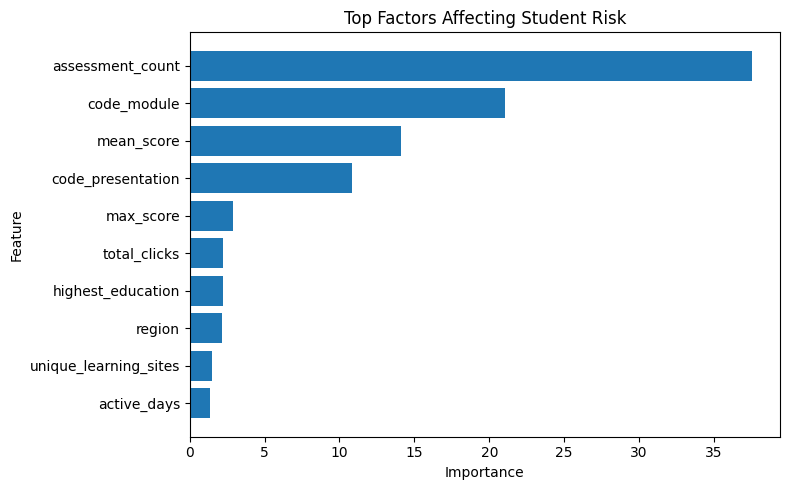

In [17]:
# ============================================================
# FEATURE IMPORTANCE
# ============================================================

if best_model_name == "CatBoost":

    importance = cat_model.get_feature_importance()

    feature_importance = pd.DataFrame({
        "Feature": X_train_cb.columns,
        "Importance": importance
    })

    feature_importance = (
        feature_importance
        .sort_values(
            "Importance",
            ascending=False
        )
    )

    display(
        feature_importance.head(10)
    )

    plt.figure(
        figsize=(8, 5)
    )

    top = feature_importance.head(10)

    plt.barh(
        top["Feature"][::-1],
        top["Importance"][::-1]
    )

    plt.xlabel(
        "Importance"
    )

    plt.ylabel(
        "Feature"
    )

    plt.title(
        "Top Factors Affecting Student Risk"
    )

    plt.tight_layout()

    plt.show()

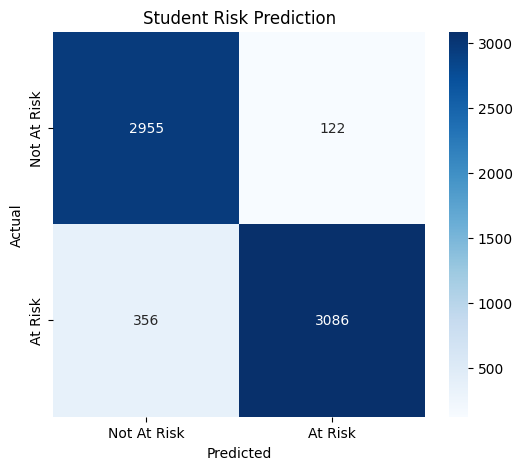

In [18]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    predictions
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not At Risk",
        "At Risk"
    ],
    yticklabels=[
        "Not At Risk",
        "At Risk"
    ]
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    "Student Risk Prediction"
)

plt.show()

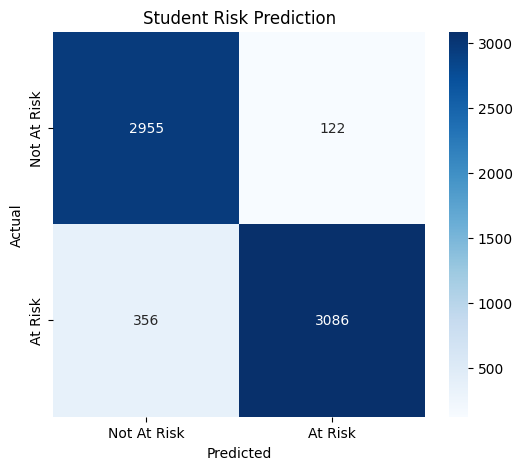

In [19]:
# ============================================================
# CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    predictions
)

plt.figure(
    figsize=(6, 5)
)

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Not At Risk",
        "At Risk"
    ],
    yticklabels=[
        "Not At Risk",
        "At Risk"
    ]
)

plt.xlabel(
    "Predicted"
)

plt.ylabel(
    "Actual"
)

plt.title(
    "Student Risk Prediction"
)

plt.show()